# Sumativa 1 - Análisis exploratorio e inferencial

**Dataset:** Framingham Heart Study (`data/framingham.csv`)
**Variable de interés:** `TenYearCHD` (1 = desarrolla enfermedad coronaria en 10 años, 0 = no)

Notebook completo del informe. Reúne las tres partes del análisis en el orden en que se presentan en el documento:

1. Parte 1: preparación de datos y estadística descriptiva.
2. Parte 2: análisis bivariado e intervalos de confianza.
3. Parte 3: pruebas de hipótesis.

Debe ejecutarse completo desde el inicio (Restart & Run All). La Parte 1 genera `data/framingham_limpio.csv`, que utiliza la Parte 2. Los gráficos se guardan en `sumativa-1/figuras/`.

## Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
np.random.seed(42)

FIG = Path("figuras")
FIG.mkdir(exist_ok=True)

COLORES = {
    "principal": "#4C72B0",
    "riesgo": "#C44E52",
    "mediana": "#55A868",
    "caja": "#8DA0CB",
    "ic": "#55A868",
}


def guardar_figura(nombre: str) -> None:
    """Ajusta el diseño, guarda la figura actual en la carpeta de figuras y la muestra."""
    plt.tight_layout()
    plt.savefig(FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")
    plt.show()

## Parte 1: Preparación de datos y estadística descriptiva

**Dataset:** Framingham Heart Study (`data/framingham.csv`)

El Framingham Heart Study es un estudio cardiovascular longitudinal realizado en Massachusetts (EE. UU.). La base contiene información demográfica, conductual y clínica de 4.240 participantes, además de indicar si desarrollaron enfermedad coronaria durante los 10 años siguientes (`TenYearCHD`). En este trabajo se busca identificar qué factores aparecen asociados con ese desenlace.

Contenido:
1. Carga y revisión de la estructura del dataset.
2. Reporte de faltantes, duplicados e inconsistencias.
3. Limpieza básica.
4. Estadística descriptiva de variables numéricas y categóricas.

### 1. Carga y estructura del dataset

In [2]:
df_raw = pd.read_csv("../data/framingham.csv")
print(f"Observaciones: {df_raw.shape[0]} | Variables: {df_raw.shape[1]}")
df_raw.head()

Observaciones: 4240 | Variables: 16


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.00,0,0.00,0.00,0,0,0,195.00,106.00,70.00,26.97,80.00,77.00,0
1,0,46,2.00,0,0.00,0.00,0,0,0,250.00,121.00,81.00,28.73,95.00,76.00,0
2,1,48,1.00,1,20.00,0.00,0,0,0,245.00,127.50,80.00,25.34,75.00,70.00,0
3,0,61,3.00,1,30.00,0.00,0,1,0,225.00,150.00,95.00,28.58,65.00,103.00,1
4,0,46,3.00,1,23.00,0.00,0,0,0,285.00,130.00,84.00,23.10,85.00,85.00,0


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


#### 1.1 Clasificación de las variables

Todas las variables vienen como números, pero varias son códigos de categorías (0/1 o niveles). Por eso se clasifican según su tipo estadístico, que define qué medidas y gráficos se usan en cada caso.

In [4]:
diccionario = pd.DataFrame([
    ("male",            "Sexo (1 = hombre, 0 = mujer)",               "Cualitativa", "Nominal (binaria)"),
    ("age",             "Edad (años)",                                "Cuantitativa", "Discreta"),
    ("education",       "Nivel educativo (1 a 4)",                    "Cualitativa", "Ordinal"),
    ("currentSmoker",   "Fumador actual (1 = sí)",                    "Cualitativa", "Nominal (binaria)"),
    ("cigsPerDay",      "Cigarrillos por día",                        "Cuantitativa", "Discreta"),
    ("BPMeds",          "Usa antihipertensivos (1 = sí)",             "Cualitativa", "Nominal (binaria)"),
    ("prevalentStroke", "Antecedente de ACV (1 = sí)",                "Cualitativa", "Nominal (binaria)"),
    ("prevalentHyp",    "Hipertensión diagnosticada (1 = sí)",        "Cualitativa", "Nominal (binaria)"),
    ("diabetes",        "Diabetes (1 = sí)",                          "Cualitativa", "Nominal (binaria)"),
    ("totChol",         "Colesterol total (mg/dL)",                   "Cuantitativa", "Continua"),
    ("sysBP",           "Presión arterial sistólica (mmHg)",          "Cuantitativa", "Continua"),
    ("diaBP",           "Presión arterial diastólica (mmHg)",         "Cuantitativa", "Continua"),
    ("BMI",             "Índice de masa corporal (kg/m²)",            "Cuantitativa", "Continua"),
    ("heartRate",       "Frecuencia cardíaca (lpm)",                  "Cuantitativa", "Discreta"),
    ("glucose",         "Glucosa (mg/dL)",                            "Cuantitativa", "Continua"),
    ("TenYearCHD",      "Enfermedad coronaria a 10 años (objetivo)",  "Cualitativa", "Nominal (binaria)"),
], columns=["variable", "descripcion", "tipo", "escala"])
diccionario

,variable,descripcion,tipo,escala
0,male,"Sexo (1 = hombre, 0 = mujer)",Cualitativa,Nominal (binaria)
1,age,Edad (años),Cuantitativa,Discreta
2,education,Nivel educativo (1 a 4),Cualitativa,Ordinal
3,currentSmoker,Fumador actual (1 = sí),Cualitativa,Nominal (binaria)
4,cigsPerDay,Cigarrillos por día,Cuantitativa,Discreta
5,BPMeds,Usa antihipertensivos (1 = sí),Cualitativa,Nominal (binaria)
6,prevalentStroke,Antecedente de ACV (1 = sí),Cualitativa,Nominal (binaria)
7,prevalentHyp,Hipertensión diagnosticada (1 = sí),Cualitativa,Nominal (binaria)
8,diabetes,Diabetes (1 = sí),Cualitativa,Nominal (binaria)
9,totChol,Colesterol total (mg/dL),Cuantitativa,Continua


In [5]:
NUM = diccionario.query("tipo == 'Cuantitativa'")["variable"].tolist()
CAT = diccionario.query("tipo == 'Cualitativa'")["variable"].tolist()
ORDINALES = diccionario.query("escala == 'Ordinal'")["variable"].tolist()
print("Numéricas:", NUM)
print("Categóricas:", CAT)

Numéricas: ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Categóricas: ['male', 'education', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'TenYearCHD']


### 2. Reporte de calidad de los datos

#### 2.1 Valores faltantes

In [6]:
faltantes = pd.DataFrame({
    "n_faltantes": df_raw.isna().sum(),
    "porcentaje": df_raw.isna().mean() * 100,
}).query("n_faltantes > 0").sort_values("n_faltantes", ascending=False)

filas_incompletas = df_raw.isna().any(axis=1).sum()
print(f"Filas con al menos un faltante: {filas_incompletas} ({filas_incompletas / len(df_raw):.1%})")
faltantes

Filas con al menos un faltante: 582 (13.7%)


,n_faltantes,porcentaje
glucose,388,9.15
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


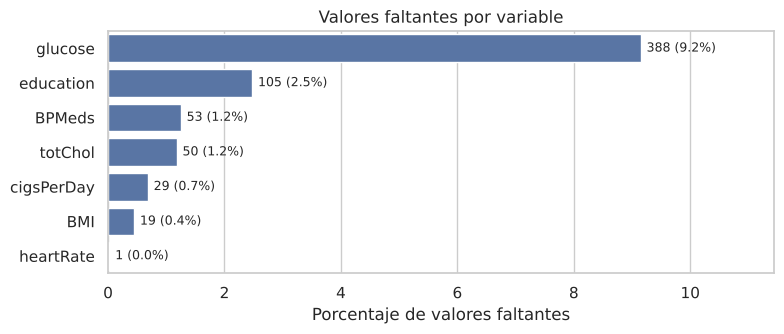

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=faltantes["porcentaje"], y=faltantes.index, color=COLORES["principal"], ax=ax)
for i, (n, p) in enumerate(zip(faltantes["n_faltantes"], faltantes["porcentaje"])):
    ax.text(p + 0.1, i, f"{n} ({p:.1f}%)", va="center", fontsize=9)
ax.set(xlabel="Porcentaje de valores faltantes", ylabel="", title="Valores faltantes por variable")
ax.set_xlim(0, faltantes["porcentaje"].max() * 1.25)
guardar_figura("p1_fig1_faltantes")

Siete variables presentan valores faltantes. La más afectada es `glucose` (9,2 %), seguida de `education` (2,5 %); el resto no supera el 1,5 %. En total, 582 filas (13,7 %) tienen al menos un faltante, por lo que eliminarlas significaría perder una parte importante de la muestra.

#### 2.2 Registros duplicados

In [8]:
duplicados = df_raw.duplicated().sum()
print(f"Filas duplicadas: {duplicados}")

Filas duplicadas: 0


No hay registros duplicados.

#### 2.3 Inconsistencias y valores atípicos

Se revisan reglas de coherencia entre variables y se cuentan los valores atípicos con el criterio de Tukey (valores fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR).

In [9]:
reglas = {
    "No fumador con cigsPerDay > 0":              (df_raw["currentSmoker"] == 0) & (df_raw["cigsPerDay"] > 0),
    "Fumador con cigsPerDay = 0":                 (df_raw["currentSmoker"] == 1) & (df_raw["cigsPerDay"] == 0),
    "Fumador con cigsPerDay faltante":            (df_raw["currentSmoker"] == 1) & (df_raw["cigsPerDay"].isna()),
    "Presión diastólica ≥ sistólica":             df_raw["diaBP"] >= df_raw["sysBP"],
    "Usa antihipertensivos sin hipertensión":     (df_raw["BPMeds"] == 1) & (df_raw["prevalentHyp"] == 0),
    "Sin diagnóstico de diabetes y glucosa ≥ 126": (df_raw["diabetes"] == 0) & (df_raw["glucose"] >= 126),
}
pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="casos").to_frame()

,casos
No fumador con cigsPerDay > 0,0
Fumador con cigsPerDay = 0,0
Fumador con cigsPerDay faltante,29
Presión diastólica ≥ sistólica,0
Usa antihipertensivos sin hipertensión,0
Sin diagnóstico de diabetes y glucosa ≥ 126,22


In [10]:
def atipicos_tukey(s: pd.Series) -> int:
    """Cuenta los valores fuera del rango [Q1 - 1,5·IQR, Q3 + 1,5·IQR] (criterio de Tukey)."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.DataFrame({
    "n_atipicos": {c: atipicos_tukey(df_raw[c]) for c in NUM},
    "minimo": df_raw[NUM].min(),
    "maximo": df_raw[NUM].max(),
})

,n_atipicos,minimo,maximo
age,0,32.00,70.00
cigsPerDay,12,0.00,70.00
totChol,56,107.00,696.00
sysBP,126,83.50,295.00
diaBP,77,48.00,142.50
BMI,97,15.54,56.80
heartRate,76,44.00,143.00
glucose,188,40.00,394.00


Hallazgos:
- No hay contradicciones lógicas entre `currentSmoker` y `cigsPerDay`, ni entre presión sistólica y diastólica.
- Los 29 faltantes de `cigsPerDay` corresponden todos a fumadores, es decir, se sabe que fuman pero no cuánto.
- 22 participantes sin diagnóstico de diabetes presentan glucosa ≥ 126 mg/dL. No se tratan como errores, porque pueden ser casos de diabetes no diagnosticada o una medición aislada.
- Hay valores atípicos en todas las variables clínicas (por ejemplo, colesterol de 696 mg/dL, glucosa de 394 mg/dL o presión sistólica de 295 mmHg). Son valores extremos, pero posibles en pacientes con enfermedades severas, por lo que se conservan. Por esto se reportan también la mediana y el IQR, que no se ven afectados por ellos.

### 3. Limpieza básica

Decisiones:

1. Los 29 faltantes de `cigsPerDay` entre fumadores se imputan con la mediana del mismo grupo (20 cigarrillos). La mediana global es 0 y no resulta adecuada porque se sabe que esas personas sí fuman.
2. Los demás faltantes se mantienen. Cada análisis trabaja con las observaciones disponibles en las variables que utiliza. Eliminar todas las filas incompletas reduciría la muestra en un 13,7 %.
3. Los valores atípicos se conservan porque son posibles desde el punto de vista clínico.
4. Las variables binarias y `education` se convierten a enteros con soporte de faltantes (`Int64`). También se crean etiquetas legibles para las tablas y gráficos.

Este manejo hace que el tamaño de la muestra cambie entre análisis. Además, si la falta de datos está relacionada con el estado de salud, las estimaciones podrían quedar sesgadas. Por esta razón se informa el número de observaciones utilizado en cada resultado.

In [11]:
df = df_raw.copy()

mediana_fumadores = df.loc[df["currentSmoker"] == 1, "cigsPerDay"].median()
mask = (df["currentSmoker"] == 1) & (df["cigsPerDay"].isna())
df.loc[mask, "cigsPerDay"] = mediana_fumadores
print(f"cigsPerDay imputados: {mask.sum()} (mediana de fumadores = {mediana_fumadores:.0f})")

for c in CAT:
    df[c] = df[c].astype("Int64")

df.to_csv("../data/framingham_limpio.csv", index=False)
print(f"Dataset limpio: {df.shape[0]} filas | faltantes restantes: {df.isna().sum().sum()}")

cigsPerDay imputados: 29 (mediana de fumadores = 20)
Dataset limpio: 4240 filas | faltantes restantes: 616


In [12]:
ETIQUETAS = {
    "male": {0: "Mujer", 1: "Hombre"},
    "education": {1: "Secundaria incompleta", 2: "Secundaria completa",
                  3: "Técnica / univ. incompleta", 4: "Universitaria"},
    "currentSmoker": {0: "No", 1: "Sí"},
    "BPMeds": {0: "No", 1: "Sí"},
    "prevalentStroke": {0: "No", 1: "Sí"},
    "prevalentHyp": {0: "No", 1: "Sí"},
    "diabetes": {0: "No", 1: "Sí"},
    "TenYearCHD": {0: "No", 1: "Sí"},
}
NOMBRES = dict(zip(diccionario["variable"], diccionario["descripcion"]))

### 4. Estadística descriptiva: variables numéricas

#### 4.1 Medidas de tendencia central, dispersión y forma

In [13]:
def resumen_numerico(s: pd.Series) -> pd.Series:
    """Calcula medidas de tendencia central, dispersión y forma de una variable numérica."""
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "n": s.count(),
        "media": s.mean(),
        "mediana": s.median(),
        "moda": s.mode().iloc[0],
        "desv_est": s.std(),
        "CV_%": s.std() / s.mean() * 100,
        "min": s.min(),
        "Q1": q1,
        "Q3": q3,
        "max": s.max(),
        "IQR": q3 - q1,
        "asimetria": s.skew(),
        "curtosis": s.kurt(),
    })

tabla_num = df[NUM].apply(resumen_numerico).T
tabla_num["n"] = tabla_num["n"].astype(int)
tabla_num

,n,media,mediana,moda,desv_est,CV_%,min,Q1,Q3,max,IQR,asimetria,curtosis
age,4240,49.58,49.00,40.00,8.57,17.29,32.00,42.00,56.00,70.00,14.00,0.23,-0.99
cigsPerDay,4240,9.08,0.00,0.00,11.92,131.22,0.00,0.00,20.00,70.00,20.00,1.23,0.97
totChol,4190,236.70,234.00,240.00,44.59,18.84,107.00,206.00,263.00,696.00,57.00,0.87,4.13
sysBP,4240,132.35,128.00,120.00,22.03,16.65,83.50,117.00,144.00,295.00,27.00,1.15,2.16
diaBP,4240,82.90,82.00,80.00,11.91,14.37,48.00,75.00,90.00,142.50,15.00,0.71,1.28
BMI,4221,25.80,25.40,22.19,4.08,15.81,15.54,23.07,28.04,56.80,4.97,0.98,2.66
heartRate,4239,75.88,75.00,75.00,12.03,15.85,44.00,68.00,83.00,143.00,15.00,0.64,0.91
glucose,3852,81.96,78.00,75.00,23.95,29.23,40.00,71.00,87.00,394.00,16.00,6.21,58.70


Interpretación:
- Edad: los participantes tienen entre 32 y 70 años, con media de 49,6 y mediana de 49. Media y mediana casi coinciden y la asimetría es cercana a 0, así que la distribución es aproximadamente simétrica y algo aplanada (curtosis negativa).
- Presión sistólica (`sysBP`), colesterol (`totChol`) e IMC (`BMI`): tienen asimetría positiva (media mayor que la mediana), con una cola de pacientes con valores altos. Su variabilidad relativa es moderada (CV entre 15 % y 19 %). La mediana del IMC (25,4 kg/m²) coincide con el punto de corte poblacional de sobrepeso en adultos de la OMS. La mediana del colesterol total es 234 mg/dL; el valor de 240 mg/dL se usa más adelante solo como referencia descriptiva general.
- Glucosa: es la variable más asimétrica (asimetría de 6,2) y con colas más pesadas (curtosis de 58,7). La mayoría de los valores está cerca de 78 mg/dL, pero hay algunos casos muy altos. En esta variable la mediana y el IQR representan mejor el valor típico que la media y la desviación estándar.
- Cigarrillos por día: la mediana es 0 porque cerca de la mitad no fuma, y el CV supera el 130 %. Como tiene muchos ceros, se describe también solo para los fumadores (mediana de 20 cigarrillos, un paquete diario).

#### 4.2 Distribuciones

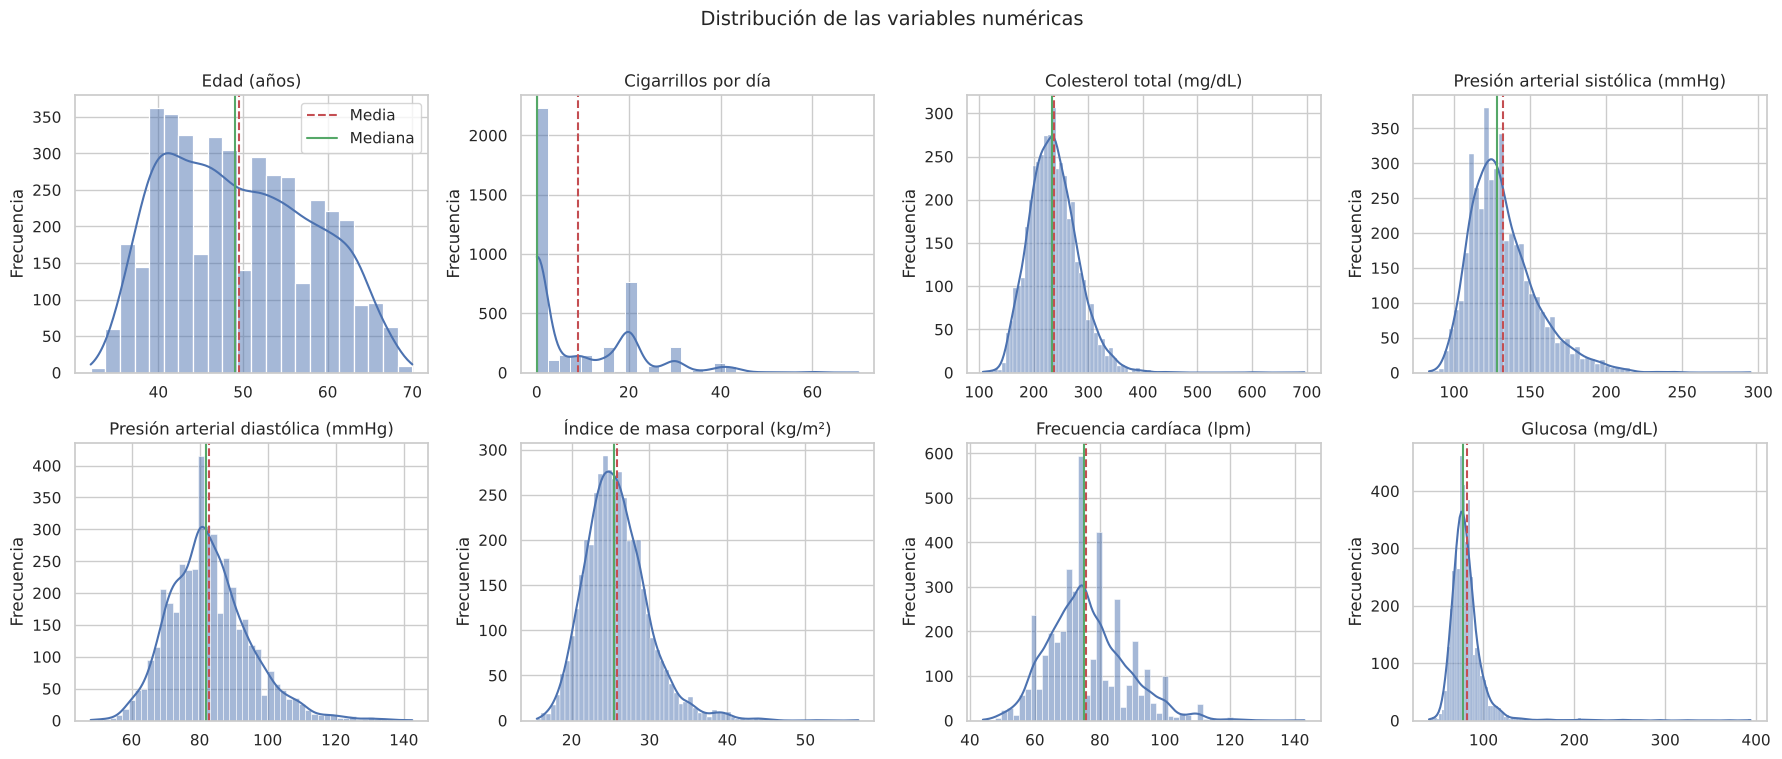

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7.5))
for ax, c in zip(axes.ravel(), NUM):
    sns.histplot(df[c].dropna(), kde=True, ax=ax, color=COLORES["principal"], edgecolor="white")
    ax.axvline(df[c].mean(), color=COLORES["riesgo"], ls="--", lw=1.5, label="Media")
    ax.axvline(df[c].median(), color=COLORES["mediana"], ls="-", lw=1.5, label="Mediana")
    ax.set(title=NOMBRES[c], xlabel="", ylabel="Frecuencia")
axes[0, 0].legend()
plt.suptitle("Distribución de las variables numéricas", fontsize=14, y=1.01)
guardar_figura("p1_fig2_histogramas")

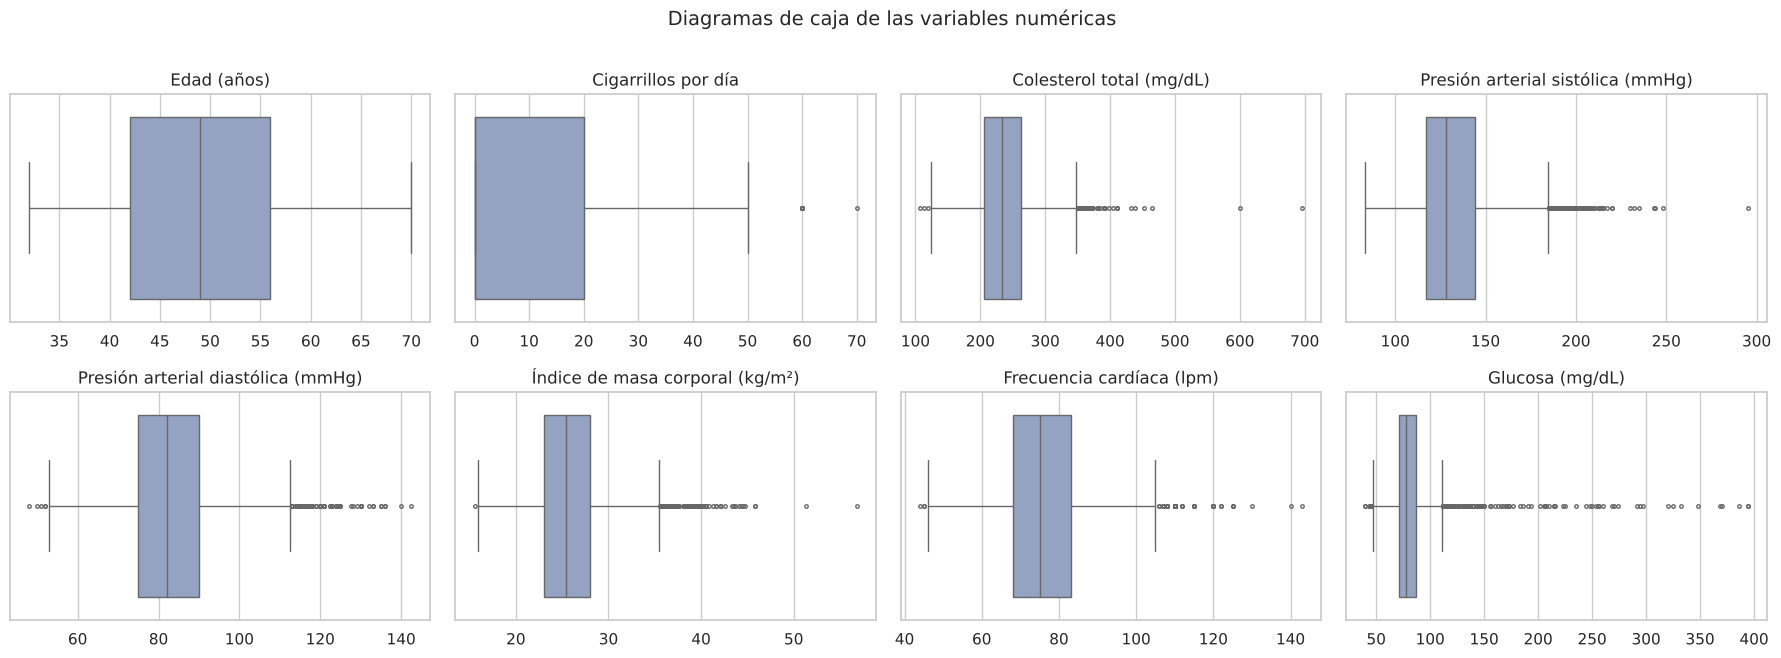

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(18, 6.5))
for ax, c in zip(axes.ravel(), NUM):
    sns.boxplot(x=df[c], ax=ax, color=COLORES["caja"], fliersize=2.5)
    ax.set(title=NOMBRES[c], xlabel="")
plt.suptitle("Diagramas de caja de las variables numéricas", fontsize=14, y=1.01)
guardar_figura("p1_fig3_boxplots")

Los histogramas coinciden con la tabla: la edad es aproximadamente simétrica, mientras que la presión, el colesterol, el IMC y en especial la glucosa tienen cola hacia la derecha (la media queda a la derecha de la mediana). En los diagramas de caja los atípicos están en el extremo superior, que corresponde a pacientes con valores clínicos de mayor riesgo.

In [16]:
fumadores = df.loc[df["currentSmoker"] == 1, "cigsPerDay"]
print("Cigarrillos por día (solo fumadores):")
resumen_numerico(fumadores).round(2).to_frame("solo fumadores").T.astype({"n": int})

Cigarrillos por día (solo fumadores):


,n,media,mediana,moda,desv_est,CV_%,min,Q1,Q3,max,IQR,asimetria,curtosis
solo fumadores,2095,18.38,20.00,20.00,10.79,58.72,1.00,10.00,20.00,70.00,10.00,0.73,0.93


#### 4.3 Umbrales descriptivos de referencia

Se calcula el porcentaje de observaciones que alcanza algunos puntos de corte publicados para adultos. Estos porcentajes describen la muestra y **no constituyen diagnósticos individuales**: la base no documenta, por ejemplo, si la glucosa fue tomada en ayunas ni si la presión se confirmó en días diferentes.

Referencias:
- Organización Mundial de la Salud, hipertensión (≥ 140/90 mmHg y confirmación en días diferentes): https://www.who.int/news-room/fact-sheets/detail/hypertension
- Organización Mundial de la Salud, sobrepeso y obesidad en adultos (IMC ≥ 25 y ≥ 30 kg/m²): https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
- MedlinePlus/NIH, colesterol total alto (≥ 240 mg/dL): https://medlineplus.gov/spanish/ency/article/007813.htm
- NIDDK/NIH, glucosa plasmática en ayunas (≥ 126 mg/dL, con repetición para confirmar): https://www.niddk.nih.gov/health-information/professionals/clinical-tools-patient-management/diabetes/diabetes-prediabetes

In [17]:
def porcentaje_sobre_umbral(s: pd.Series, umbral: float) -> float:
    """Porcentaje de valores observados (sin faltantes) mayores o iguales al umbral."""
    s = s.dropna()
    return (s >= umbral).mean() * 100


UMBRALES = [
    ("Presión sistólica ≥ 140 mmHg", "sysBP", 140),
    ("Colesterol total ≥ 240 mg/dL", "totChol", 240),
    ("IMC ≥ 25 (sobrepeso u obesidad)", "BMI", 25),
    ("IMC ≥ 30 (obesidad)", "BMI", 30),
    ("Glucosa ≥ 126 mg/dL", "glucose", 126),
]
pd.Series(
    {etiqueta: porcentaje_sobre_umbral(df[col], u) for etiqueta, col, u in UMBRALES},
    name="% de participantes",
).round(1).to_frame()

,% de participantes
Presión sistólica ≥ 140 mmHg,30.30
Colesterol total ≥ 240 mg/dL,44.90
IMC ≥ 25 (sobrepeso u obesidad),54.30
IMC ≥ 30 (obesidad),12.80
Glucosa ≥ 126 mg/dL,2.20


El 30,3 % de las observaciones tiene presión sistólica ≥ 140 mmHg, el 44,9 % colesterol total ≥ 240 mg/dL y el 54,3 % IMC ≥ 25 kg/m². Son porcentajes descriptivos de esta muestra y no prevalencias diagnósticas. En particular, una medición aislada de presión o glucosa no permite diagnosticar hipertensión o diabetes.

### 5. Estadística descriptiva: variables categóricas

#### 5.1 Frecuencias absolutas y relativas

In [18]:
def tabla_frecuencias(datos: pd.DataFrame, c: str) -> pd.DataFrame:
    """Frecuencias absolutas y relativas de una variable categórica (acumuladas si es ordinal)."""
    s = datos[c].map(ETIQUETAS[c]).fillna("Sin dato")
    t = s.value_counts().to_frame("frec_absoluta")
    t["frec_relativa_%"] = t["frec_absoluta"] / len(s) * 100
    if c in ORDINALES:
        orden = list(ETIQUETAS[c].values()) + (["Sin dato"] if "Sin dato" in t.index else [])
        t = t.loc[orden]
        t["frec_acumulada_%"] = t["frec_relativa_%"].cumsum()
    t.index.name = c
    return t

for c in CAT:
    print(f"\n{NOMBRES[c]}")
    display(tabla_frecuencias(df, c))


Sexo (1 = hombre, 0 = mujer)


,frec_absoluta,frec_relativa_%
male,,
Mujer,2420,57.08
Hombre,1820,42.92



Nivel educativo (1 a 4)


,frec_absoluta,frec_relativa_%,frec_acumulada_%
education,,,
Secundaria incompleta,1720,40.57,40.57
Secundaria completa,1253,29.55,70.12
Técnica / univ. incompleta,689,16.25,86.37
Universitaria,473,11.16,97.52
Sin dato,105,2.48,100.00



Fumador actual (1 = sí)


...

,frec_absoluta,frec_relativa_%
prevalentHyp,,
No,2923,68.94
Sí,1317,31.06



Diabetes (1 = sí)


,frec_absoluta,frec_relativa_%
diabetes,,
No,4131,97.43
Sí,109,2.57



Enfermedad coronaria a 10 años (objetivo)


,frec_absoluta,frec_relativa_%
TenYearCHD,,
No,3596,84.81
Sí,644,15.19


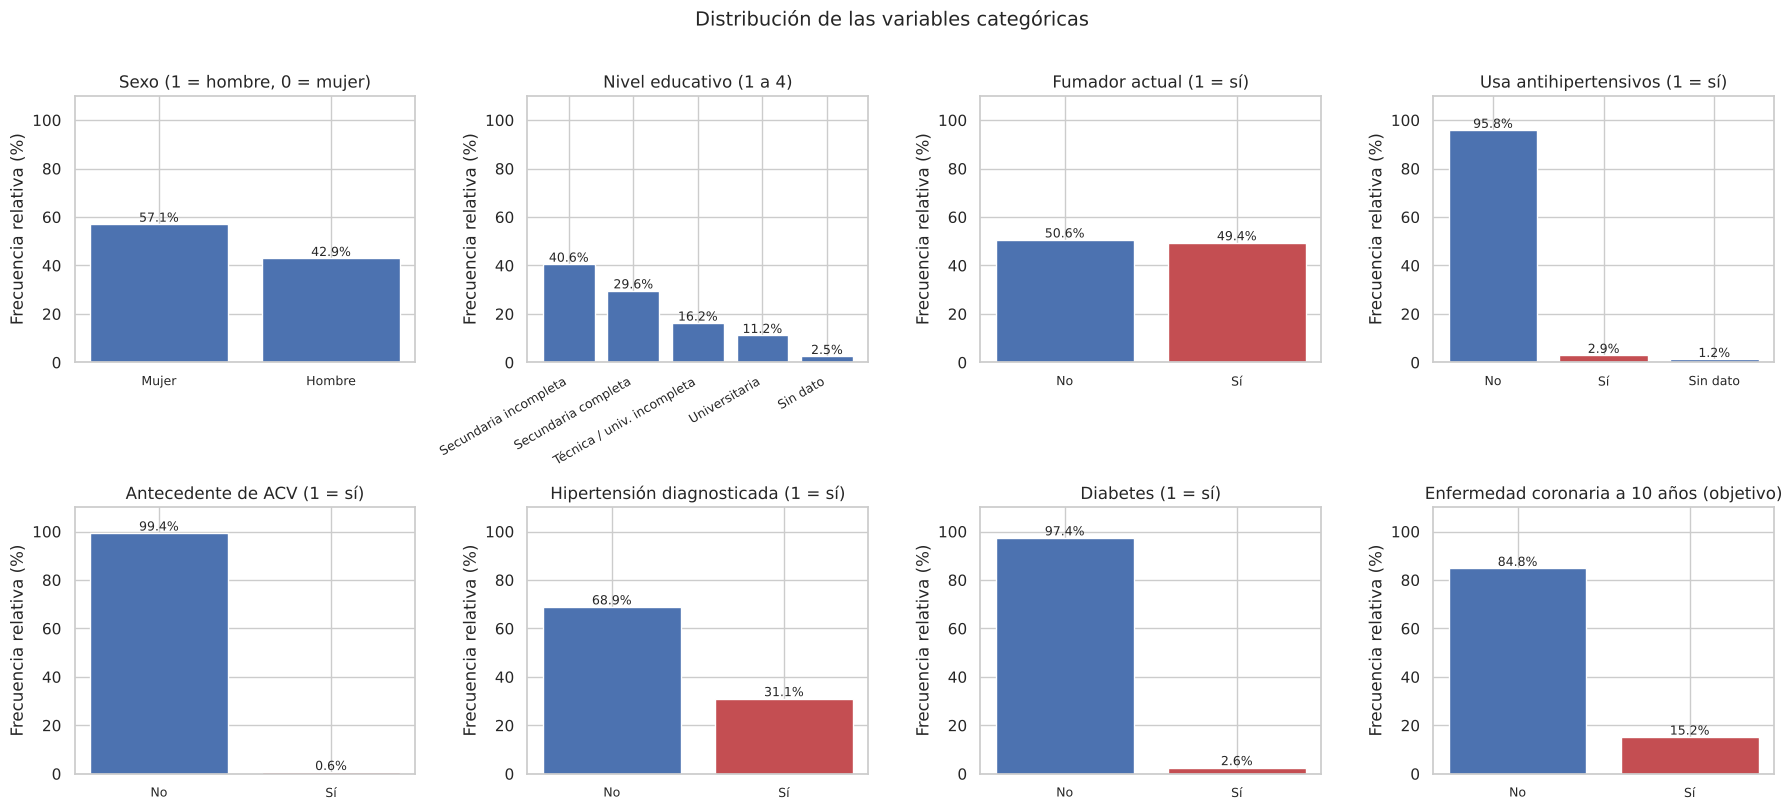

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), CAT):
    t = tabla_frecuencias(df, c)
    colores = [COLORES["riesgo"] if i == "Sí" else COLORES["principal"] for i in t.index]
    ax.bar(range(len(t)), t["frec_relativa_%"], color=colores)
    ordinal = c in ORDINALES
    ax.set_xticks(range(len(t)), t.index, rotation=30 if ordinal else 0,
                  ha="right" if ordinal else "center", fontsize=9)
    for i, v in enumerate(t["frec_relativa_%"]):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set(title=NOMBRES[c], ylabel="Frecuencia relativa (%)", ylim=(0, 110))
plt.suptitle("Distribución de las variables categóricas", fontsize=14, y=1.01)
guardar_figura("p1_fig4_categoricas")

Interpretación:
- Variable objetivo (`TenYearCHD`): el 15,2 % de los participantes desarrolló enfermedad coronaria en 10 años (644 de 4.240). Las clases están desbalanceadas, algo a considerar en las fases de modelamiento predictivo.
- Sexo: predominan las mujeres (57,1 %).
- Tabaquismo: casi la mitad de la muestra fuma (49,4 %), una proporción alta propia de la época del estudio.
- Hipertensión: el 31,1 % tiene hipertensión diagnosticada y 124 participantes informan uso de antihipertensivos. Esto equivale al 9,4 % de quienes tienen hipertensión registrada; como `BPMeds` tiene 53 valores faltantes, no corresponde interpretar los faltantes como ausencia de tratamiento.
- Diabetes (2,6 %) y antecedente de ACV (0,6 %): son poco frecuentes, por lo que los análisis que las usen tendrán más incertidumbre.
- Educación: el nivel más frecuente es secundaria incompleta (40,6 %), y la frecuencia disminuye a medida que aumenta el nivel educativo.

### 6. Síntesis

- La base tiene 4.240 registros y 16 variables. No se encontraron filas exactamente duplicadas ni contradicciones en las reglas de coherencia revisadas.
- Siete variables del archivo original tienen faltantes; `glucose` es la más afectada, con un 9,2 %.
- Se imputaron 29 valores de cigarrillos por día y se conservaron los valores extremos. Los demás análisis usan los casos disponibles.
- Varias variables clínicas presentan asimetría positiva. En esos casos la mediana y el IQR describen mejor el centro y la dispersión, especialmente para la glucosa.
- La tasa observada de enfermedad coronaria es 15,2 %. Los resultados describen esta cohorte histórica y no pueden generalizarse directamente a otras poblaciones.

## Parte 2: Análisis bivariado e intervalos de confianza

**Dataset:** Framingham Heart Study (`data/framingham_limpio.csv`)  
**Variable de interés:** `TenYearCHD` (1 = desarrolla enfermedad coronaria en 10 años, 0 = no)

En esta parte se revisan las relaciones entre las variables y se comparan los participantes según el desarrollo de enfermedad coronaria. También se estiman medias y proporciones con intervalos de confianza al 95 %. Los resultados corresponden a asociaciones observadas y no permiten establecer causalidad.

Contenido:
1. Disponibilidad de los datos.
2. Correlaciones entre variables numéricas.
3. Comparaciones según `TenYearCHD`.
4. Estimaciones puntuales e intervalos de confianza.
5. Limitaciones y pasos siguientes.

### 0. Carga de datos

In [20]:
df = pd.read_csv("../data/framingham_limpio.csv")
NUM = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
NOMBRES = {
    "age": "Edad (años)", "cigsPerDay": "Cigarrillos por día",
    "totChol": "Colesterol total (mg/dL)", "sysBP": "Presión sistólica (mmHg)",
    "diaBP": "Presión diastólica (mmHg)", "BMI": "IMC (kg/m²)",
    "heartRate": "Frecuencia cardíaca (lpm)", "glucose": "Glucosa (mg/dL)",
}

print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]}")

Observaciones: 4240 | Variables: 16


### 1. Disponibilidad de datos

Se utiliza el archivo limpio generado en la Parte 1. Solo se imputaron los valores faltantes de `cigsPerDay`; las demás variables mantienen sus faltantes. En cada cálculo se usan los casos disponibles y se informa el tamaño de muestra correspondiente.

In [21]:
disponibilidad = pd.DataFrame({
    "n_observado": df[NUM].count(),
    "n_faltante": df[NUM].isna().sum(),
    "%_faltante": df[NUM].isna().mean().mul(100),
})
disponibilidad.index = [NOMBRES[c] for c in disponibilidad.index]
disponibilidad.round(2)

,n_observado,n_faltante,%_faltante
Edad (años),4240,0,0.00
Cigarrillos por día,4240,0,0.00
Colesterol total (mg/dL),4190,50,1.18
Presión sistólica (mmHg),4240,0,0.00
Presión diastólica (mmHg),4240,0,0.00
IMC (kg/m²),4221,19,0.45
Frecuencia cardíaca (lpm),4239,1,0.02
Glucosa (mg/dL),3852,388,9.15


`glucose` tiene el menor tamaño muestral (n = 3.852), mientras que edad, cigarrillos, presión sistólica y diastólica están disponibles para las 4.240 observaciones. Esta diferencia debe considerarse al comparar precisión entre estimaciones.

### 2. Relación entre variables numéricas

Se usa la correlación de Spearman porque varias variables son asimétricas, contienen valores extremos o concentran muchos ceros. El coeficiente se calcula a partir de rangos y permite detectar relaciones monótonas sin exigir normalidad. Cada par se calcula con las observaciones disponibles en ambas variables.

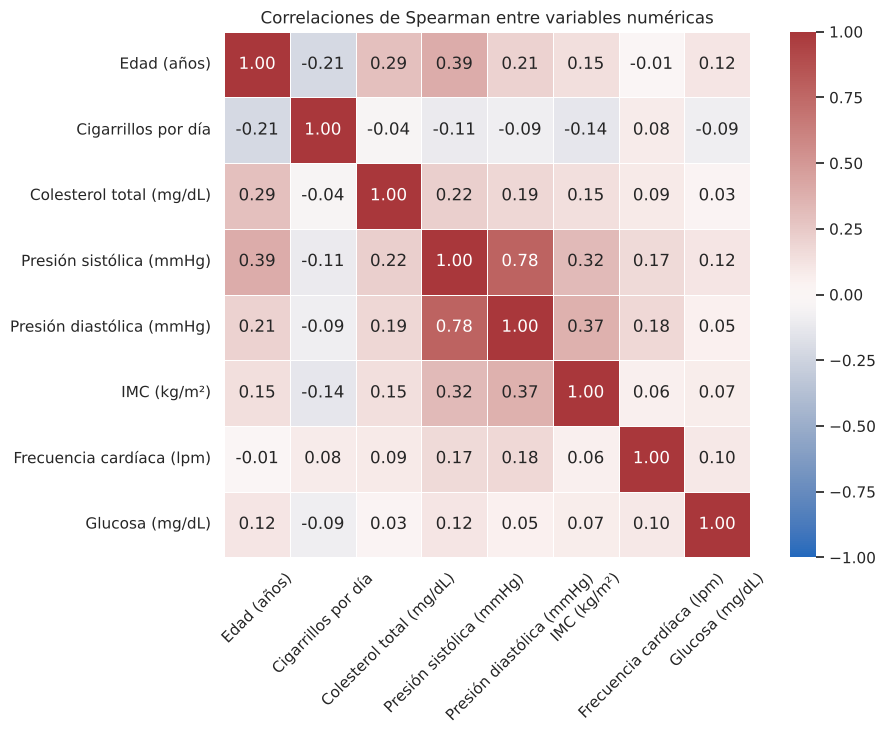

In [22]:
corr = df[NUM].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, ax=ax,
            xticklabels=[NOMBRES[c] for c in NUM],
            yticklabels=[NOMBRES[c] for c in NUM])
ax.set_title("Correlaciones de Spearman entre variables numéricas")
ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)
guardar_figura("p2_fig1_correlaciones")

In [23]:
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
              .stack().rename("rho").reset_index())
pares["abs_rho"] = pares["rho"].abs()
pares = pares.sort_values("abs_rho", ascending=False).drop(columns="abs_rho")
pares.head(10)

,level_0,level_1,rho
28,sysBP,diaBP,0.78
3,age,sysBP,0.39
37,diaBP,BMI,0.37
29,sysBP,BMI,0.32
2,age,totChol,0.29
19,totChol,sysBP,0.22
1,age,cigsPerDay,-0.21
4,age,diaBP,0.21
20,totChol,diaBP,0.19
38,diaBP,heartRate,0.18


La correlación más alta corresponde a la presión sistólica y diastólica (ρ = 0,78), lo que resulta esperable porque ambas miden componentes de la presión arterial. También se observa una relación moderada entre edad y presión sistólica (ρ = 0,39), y entre IMC y presión diastólica (ρ = 0,37). El resto de los coeficientes es bajo. Estas relaciones pueden estar afectadas por otras variables y no indican causalidad.

### 3. Variables numéricas y enfermedad coronaria

Para cada variable se comparan las medias de quienes desarrollaron CHD y quienes no. Se informa la diferencia `CHD − sin CHD`, su intervalo de confianza del 95 % calculado con el método de Welch y el tamaño del efecto *g* de Hedges. Las dos pruebas de hipótesis exigidas en la evaluación se desarrollan en la Parte 3.

In [24]:
def comparacion_chd(variable: str) -> pd.Series:
    # Resumen bivariado, IC de Welch y g de Hedges para CHD frente a no CHD.
    con_chd = df.loc[df["TenYearCHD"] == 1, variable].dropna()
    sin_chd = df.loc[df["TenYearCHD"] == 0, variable].dropna()
    prueba = stats.ttest_ind(con_chd, sin_chd, equal_var=False)
    ic = prueba.confidence_interval(confidence_level=0.95)
    n1, n0 = len(con_chd), len(sin_chd)
    sd_comb = np.sqrt(((n1 - 1) * con_chd.var() + (n0 - 1) * sin_chd.var()) / (n1 + n0 - 2))
    d = (con_chd.mean() - sin_chd.mean()) / sd_comb
    correccion = 1 - 3 / (4 * (n1 + n0) - 9)
    return pd.Series({
        "n_sin_CHD": n0, "n_con_CHD": n1,
        "media_sin_CHD": sin_chd.mean(), "media_con_CHD": con_chd.mean(),
        "diferencia": con_chd.mean() - sin_chd.mean(),
        "IC95_inf": ic.low, "IC95_sup": ic.high,
        "g_Hedges": correccion * d,
    })


tabla_bivariada = pd.DataFrame({c: comparacion_chd(c) for c in NUM}).T
tabla_bivariada.index = [NOMBRES[c] for c in tabla_bivariada.index]
tabla_bivariada[["n_sin_CHD", "n_con_CHD"]] = tabla_bivariada[["n_sin_CHD", "n_con_CHD"]].astype(int)
tabla_bivariada.round(2)

,n_sin_CHD,n_con_CHD,media_sin_CHD,media_con_CHD,diferencia,IC95_inf,IC95_sup,g_Hedges
Edad (años),3596,644,48.76,54.15,5.38,4.71,6.06,0.64
Cigarrillos por día,3596,644,8.80,10.66,1.86,0.78,2.94,0.16
Colesterol total (mg/dL),3555,635,235.15,245.39,10.24,6.23,14.25,0.23
Presión sistólica (mmHg),3596,644,130.34,143.62,13.28,11.11,15.45,0.62
Presión diastólica (mmHg),3596,644,82.17,86.98,4.81,3.67,5.96,0.41
IMC (kg/m²),3587,634,25.67,26.53,0.86,0.48,1.24,0.21
Frecuencia cardíaca (lpm),3596,643,75.76,76.53,0.77,-0.26,1.79,0.06
Glucosa (mg/dL),3258,594,80.68,89.01,8.33,4.95,11.71,0.35


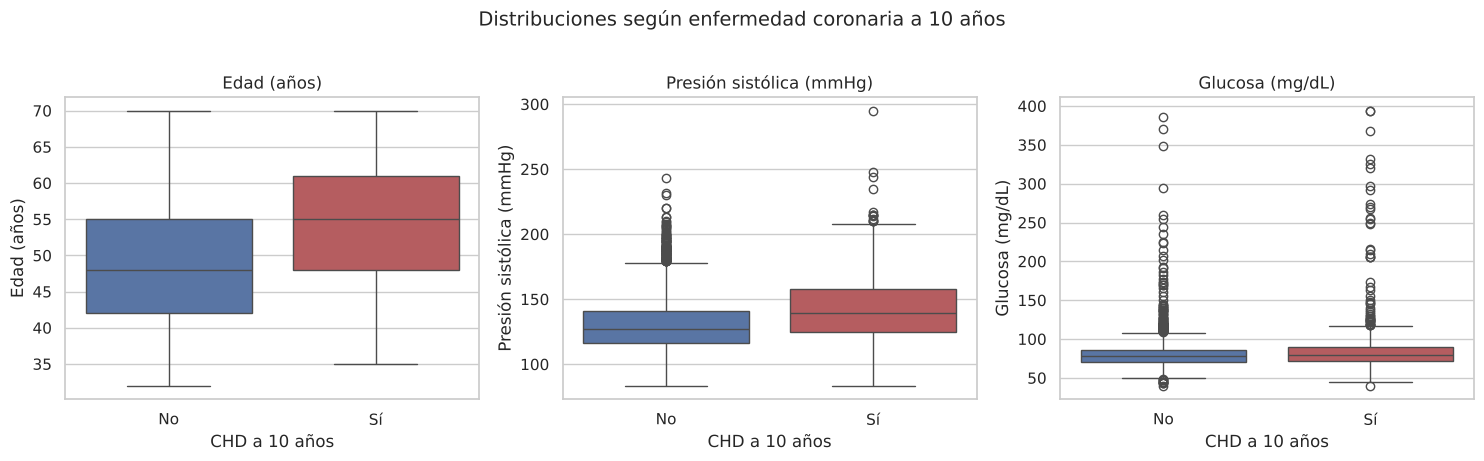

In [25]:
seleccion = ["age", "sysBP", "glucose"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, variable in zip(axes, seleccion):
    sns.boxplot(data=df, x="TenYearCHD", y=variable, hue="TenYearCHD",
                legend=False, palette=[COLORES["principal"], COLORES["riesgo"]], ax=ax)
    ax.set_xticks([0, 1], ["No", "Sí"])
    ax.set(xlabel="CHD a 10 años", ylabel=NOMBRES[variable], title=NOMBRES[variable])
plt.suptitle("Distribuciones según enfermedad coronaria a 10 años", fontsize=14, y=1.02)
guardar_figura("p2_fig2_numericas_chd")

Las mayores diferencias estandarizadas se observan en edad (*g* ≈ 0,64) y presión sistólica (*g* ≈ 0,62): el grupo con CHD tiene en promedio 5,4 años más y 13,3 mmHg adicionales. La glucosa también es mayor en el grupo con CHD, pero su distribución es muy asimétrica y contiene menos casos observados. La frecuencia cardíaca muestra una diferencia pequeña cuyo IC incluye cero. Ninguna comparación está ajustada por edad, sexo u otros factores.

### 4. Variables categóricas y enfermedad coronaria

Se calculan las tasas de CHD para algunos grupos de interés. Los intervalos se obtienen con el método de Wilson, que es más estable que la aproximación normal cuando hay pocos casos.

In [26]:
CATEGORICAS = {
    "male": {0: "Mujer", 1: "Hombre"},
    "currentSmoker": {0: "No fumador", 1: "Fumador"},
    "prevalentHyp": {0: "Sin hipertensión", 1: "Con hipertensión"},
    "diabetes": {0: "Sin diabetes", 1: "Con diabetes"},
    "prevalentStroke": {0: "Sin ACV previo", 1: "Con ACV previo"},
}


def tasa_chd(variable: str, valor: int, etiqueta: str) -> dict:
    grupo = df.loc[df[variable] == valor, "TenYearCHD"].dropna()
    eventos, n = int(grupo.sum()), int(grupo.count())
    inferior, superior = proportion_confint(eventos, n, alpha=0.05, method="wilson")
    return {
        "variable": variable, "grupo": etiqueta, "n": n, "eventos": eventos,
        "tasa_%": eventos / n * 100, "IC95_inf_%": inferior * 100, "IC95_sup_%": superior * 100,
    }


filas = []
for variable, etiquetas in CATEGORICAS.items():
    for valor, etiqueta in etiquetas.items():
        filas.append(tasa_chd(variable, valor, etiqueta))

tabla_tasas = pd.DataFrame(filas)
tabla_tasas.round(2)

,variable,grupo,n,eventos,tasa_%,IC95_inf_%,IC95_sup_%
0,male,Mujer,2420,301,12.44,11.18,13.81
1,male,Hombre,1820,343,18.85,17.12,20.71
2,currentSmoker,No fumador,2145,311,14.50,13.07,16.05
3,currentSmoker,Fumador,2095,333,15.89,14.39,17.52
4,prevalentHyp,Sin hipertensión,2923,319,10.91,9.83,12.10
5,prevalentHyp,Con hipertensión,1317,325,24.68,22.42,27.08
6,diabetes,Sin diabetes,4131,604,14.62,13.58,15.73
7,diabetes,Con diabetes,109,40,36.70,28.25,46.05
8,prevalentStroke,Sin ACV previo,4215,633,15.02,13.97,16.13
9,prevalentStroke,Con ACV previo,25,11,44.00,26.67,62.93


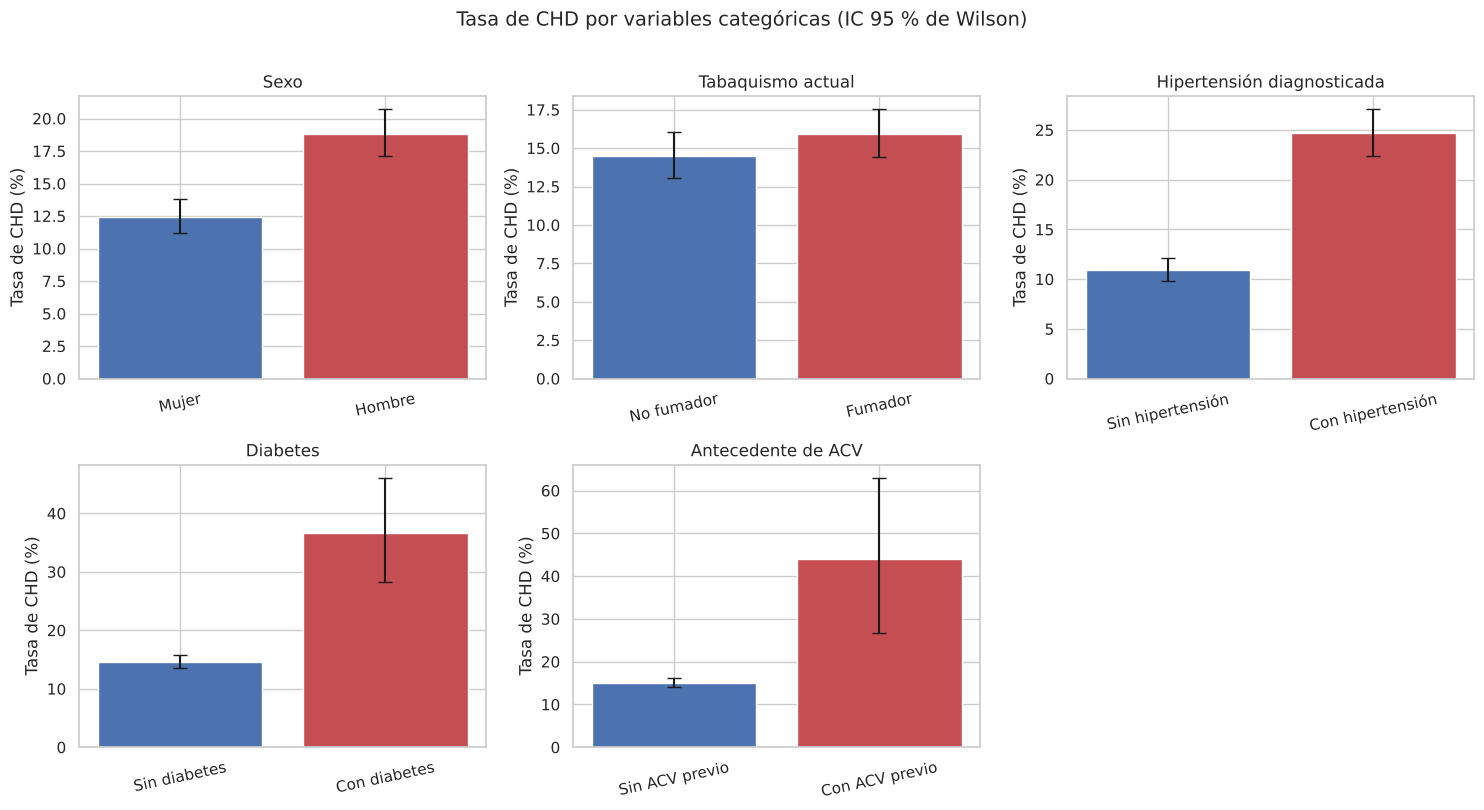

In [27]:
TITULOS_CAT = {
    "male": "Sexo",
    "currentSmoker": "Tabaquismo actual",
    "prevalentHyp": "Hipertensión diagnosticada",
    "diabetes": "Diabetes",
    "prevalentStroke": "Antecedente de ACV",
}

orden_variables = list(CATEGORICAS)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, variable in zip(axes.ravel(), orden_variables):
    t = tabla_tasas.query("variable == @variable")
    yerr = np.vstack([t["tasa_%"] - t["IC95_inf_%"], t["IC95_sup_%"] - t["tasa_%"]])
    ax.bar(t["grupo"], t["tasa_%"], yerr=yerr, capsize=5,
           color=[COLORES["principal"], COLORES["riesgo"]])
    ax.set(ylabel="Tasa de CHD (%)", title=TITULOS_CAT[variable])
    ax.tick_params(axis="x", rotation=12)
axes.ravel()[-1].axis("off")
plt.suptitle("Tasa de CHD por variables categóricas (IC 95 % de Wilson)", fontsize=14, y=1.01)
guardar_figura("p2_fig3_tasas_chd")

La tasa de CHD es mayor entre hombres (18,8 % frente a 12,4 %), personas con hipertensión (24,7 % frente a 10,9 %) y personas con diabetes (36,7 % frente a 14,6 %). El grupo con ACV previo tiene solo 25 observaciones, por lo que su intervalo es amplio y la estimación es inestable. La diferencia cruda por tabaquismo es pequeña; la Parte 3 muestra que la edad actúa como posible confusor.

### 5. Estimaciones puntuales e intervalos de confianza

Se seleccionan edad, presión sistólica y colesterol total porque son variables numéricas directamente relacionadas con el problema cardiovascular. En los tres casos se estima la media.

El intervalo de confianza se calcula como media ± *t* crítico × error estándar. El método supone observaciones independientes. Aunque presión y colesterol no siguen una distribución normal, sus muestras superan las 4.000 observaciones, por lo que la distribución de la media puede aproximarse mediante el Teorema Central del Límite. Estos intervalos representan la variabilidad muestral, pero no corrigen posibles sesgos de selección ni problemas producidos por los datos faltantes.

In [28]:
def ic_media_t(s: pd.Series, confianza: float = 0.95) -> pd.Series:
    # Estimación de la media e IC t bilateral usando casos observados.
    s = s.dropna()
    media = s.mean()
    error = stats.sem(s)
    inferior, superior = stats.t.interval(confianza, df=len(s) - 1, loc=media, scale=error)
    return pd.Series({
        "n": len(s), "estimacion_media": media, "error_estandar": error,
        "IC95_inf": inferior, "IC95_sup": superior,
    })


VARIABLES_IC = ["age", "sysBP", "totChol"]
tabla_ic = pd.DataFrame({c: ic_media_t(df[c]) for c in VARIABLES_IC}).T
tabla_ic.index = [NOMBRES[c] for c in tabla_ic.index]
tabla_ic["n"] = tabla_ic["n"].astype(int)
tabla_ic.round(2)

,n,estimacion_media,error_estandar,IC95_inf,IC95_sup
Edad (años),4240,49.58,0.13,49.32,49.84
Presión sistólica (mmHg),4240,132.35,0.34,131.69,133.02
Colesterol total (mg/dL),4190,236.70,0.69,235.35,238.05


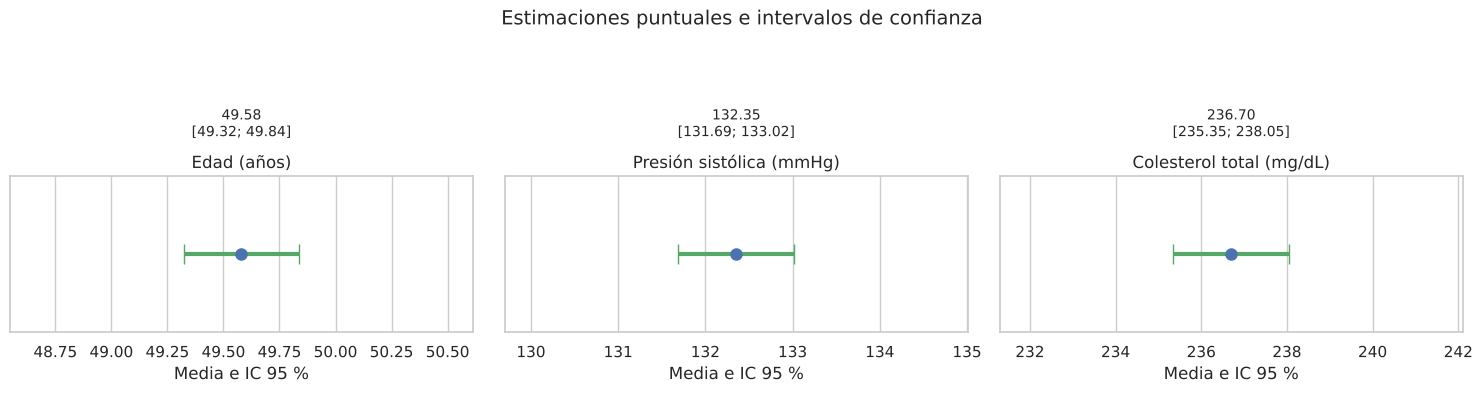

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (etiqueta, fila) in zip(axes, tabla_ic.iterrows()):
    estimacion = fila["estimacion_media"]
    inferior = fila["IC95_inf"]
    superior = fila["IC95_sup"]
    margen = max((superior - inferior) * 1.5, abs(estimacion) * 0.005)
    ax.errorbar(estimacion, 0, xerr=[[estimacion - inferior], [superior - estimacion]],
                fmt="o", markersize=8, color=COLORES["principal"],
                ecolor=COLORES["ic"], elinewidth=3, capsize=7)
    ax.set_xlim(inferior - margen, superior + margen)
    ax.set_yticks([])
    ax.set(title=etiqueta, xlabel="Media e IC 95 %")
    ax.text(estimacion, 0.08, f"{estimacion:.2f}\n[{inferior:.2f}; {superior:.2f}]",
            ha="center", va="bottom", fontsize=10)
plt.suptitle("Estimaciones puntuales e intervalos de confianza", fontsize=14, y=1.03)
guardar_figura("p2_fig4_ic_medias")

Interpretación de los intervalos:
- **Edad:** media de 49,58 años; IC 95 % [49,32; 49,84].
- **Presión sistólica:** media de 132,35 mmHg; IC 95 % [131,69; 133,02].
- **Colesterol total:** media de 236,70 mg/dL; IC 95 % [235,35; 238,05], usando 4.190 observaciones.

La interpretación frecuentista es que, al repetir el procedimiento muchas veces, aproximadamente el 95 % de los intervalos contendría la media poblacional. El tamaño de muestra explica que los intervalos sean estrechos, aunque esto no garantiza que la cohorte represente a otras poblaciones.

#### 5.1 Estimación complementaria de la proporción de CHD

In [30]:
eventos = int(df["TenYearCHD"].sum())
n = int(df["TenYearCHD"].count())
ic_prop = proportion_confint(eventos, n, alpha=0.05, method="wilson")
pd.DataFrame({
    "n": [n], "eventos": [eventos], "proporcion_estimada_%": [eventos / n * 100],
    "IC95_inf_%": [ic_prop[0] * 100], "IC95_sup_%": [ic_prop[1] * 100],
}, index=["CHD a 10 años"]).round(2)

,n,eventos,proporcion_estimada_%,IC95_inf_%,IC95_sup_%
CHD a 10 años,4240,644,15.19,14.14,16.30


La proporción observada de CHD a 10 años es 15,19 %, con IC de Wilson al 95 % [14,14 %; 16,30 %]. Esta estimación complementa las medias y ayuda a dimensionar el desbalance de la variable objetivo.

### 6. Limitaciones

- Los participantes pertenecen a una cohorte histórica de Framingham, por lo que los resultados no representan necesariamente a la población chilena ni a la población actual.
- Se trabaja con los casos disponibles. Si los faltantes están relacionados con variables clínicas, puede existir sesgo.
- Las comparaciones son crudas y no controlan simultáneamente edad, sexo, hipertensión, diabetes y tabaquismo.
- Los grupos con antecedente de ACV y diabetes tienen pocos casos y, por lo tanto, intervalos más amplios.
- Se revisan varias asociaciones con fines exploratorios. Los resultados sirven para orientar análisis posteriores, no para confirmar múltiples efectos independientes.

### 7. Síntesis y próximos pasos

- Edad y presión sistólica presentan las diferencias más marcadas entre los grupos con y sin CHD.
- Las tasas de CHD son mayores entre hombres y entre quienes tienen hipertensión o diabetes, aunque estas comparaciones aún no están ajustadas.
- Se estimaron las medias de edad, presión sistólica y colesterol total con intervalos de confianza del 95 %.
- En la Parte 3 se realizan las pruebas de hipótesis. Más adelante será necesario ajustar un modelo de regresión logística, estudiar interacciones, tratar los faltantes y validar el modelo fuera de la muestra de entrenamiento.

## Parte 3: Pruebas de hipótesis

**Dataset:** Framingham Heart Study (`data/framingham.csv`)
**Variable de interés:** `TenYearCHD` (1 = desarrolla enfermedad coronaria en 10 años, 0 = no)

Se contrastan dos hipótesis relacionadas con el riesgo de enfermedad coronaria:

1. Prueba 1: diferencia en la presión arterial sistólica media entre pacientes que desarrollan y no desarrollan enfermedad coronaria (prueba *t* de Welch para dos muestras).
2. Prueba 2: asociación entre el hábito de fumar y la enfermedad coronaria (prueba χ² de independencia).

Las variables utilizadas (`sysBP`, `currentSmoker`, `TenYearCHD`) no tienen valores faltantes, por lo que ambas pruebas usan las 4.240 observaciones del dataset original.

### 0. Carga de datos

In [31]:
df = pd.read_csv("../data/framingham.csv")
print(f"Observaciones: {df.shape[0]} | Variables: {df.shape[1]}")
df[["sysBP", "currentSmoker", "TenYearCHD"]].isna().sum()

Observaciones: 4240 | Variables: 16


sysBP            0
currentSmoker    0
TenYearCHD       0
dtype: int64

### 1. Nivel de significancia

Se usa α = 0,05, el valor habitual en investigación biomédica, que mantiene en 5 % la probabilidad de error tipo I (concluir que hay una diferencia o asociación cuando no la hay). Como la muestra es grande (n = 4.240), diferencias pequeñas pueden resultar significativas. Por eso, además del valor *p*, se reporta el tamaño del efecto para evaluar si la diferencia es relevante en la práctica.

In [32]:
ALPHA = 0.05


def decision(p_valor: float, alpha: float = ALPHA) -> str:
    """Devuelve la decisión sobre H0 comparando el valor p con el nivel de significancia."""
    return "se rechaza H0" if p_valor < alpha else "no se rechaza H0"


def d_cohen(x: pd.Series, y: pd.Series) -> float:
    """Tamaño del efecto d de Cohen para dos muestras, con desviación estándar combinada."""
    nx, ny = len(x), len(y)
    s_comb = np.sqrt(((nx - 1) * x.var() + (ny - 1) * y.var()) / (nx + ny - 2))
    return (x.mean() - y.mean()) / s_comb


def v_cramer(chi2: float, tabla: pd.DataFrame) -> float:
    """Tamaño del efecto V de Cramér para una tabla de contingencia."""
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

### 2. Prueba 1: presión sistólica y enfermedad coronaria

#### 2.1 Hipótesis

Sea μ₁ la presión sistólica media de quienes desarrollan enfermedad coronaria y μ₀ la de quienes no la desarrollan:

- **H₀:** μ₁ = μ₀ (la presión sistólica media es igual en ambos grupos)
- **H₁:** μ₁ ≠ μ₀ (la presión sistólica media difiere entre grupos)

Se plantea una prueba bilateral, ya que no se asume a priori la dirección de la diferencia.

#### 2.2 Descripción por grupo

In [33]:
chd = df.loc[df["TenYearCHD"] == 1, "sysBP"]
sano = df.loc[df["TenYearCHD"] == 0, "sysBP"]

resumen = df.groupby("TenYearCHD")["sysBP"].agg(
    n="count", media="mean", mediana="median", desv_est="std"
).round(2)
resumen.index = ["Sin CHD (0)", "Con CHD (1)"]
resumen

,n,media,mediana,desv_est
Sin CHD (0),3596,130.34,127.00,20.45
Con CHD (1),644,143.62,139.00,26.69


#### 2.3 Verificación de supuestos

1. Independencia: se considera que cada fila pertenece a una persona distinta, de acuerdo con la descripción de la base. Esto no puede verificarse directamente porque no existe un identificador de participante.
2. Normalidad: se revisa con la prueba de D'Agostino-Pearson y gráficos Q-Q. Debido al tamaño de la muestra, también se observa la forma de las distribuciones y la presencia de valores extremos.
3. Homogeneidad de varianzas: se evalúa con la prueba de Levene centrada en la mediana.

In [34]:
for nombre, x in [("Sin CHD", sano), ("Con CHD", chd)]:
    k2, p = stats.normaltest(x)
    print(f"{nombre:8s} | D'Agostino K² = {k2:7.2f} | p = {p:.2e} | asimetría = {stats.skew(x):.2f}")

lev = stats.levene(chd, sano, center="median")
print(f"\nLevene: W = {lev.statistic:.2f} | p = {lev.pvalue:.2e}")

Sin CHD  | D'Agostino K² =  592.70 | p = 1.98e-129 | asimetría = 1.06
Con CHD  | D'Agostino K² =  108.94 | p = 2.21e-24 | asimetría = 1.00

Levene: W = 65.32 | p = 8.23e-16


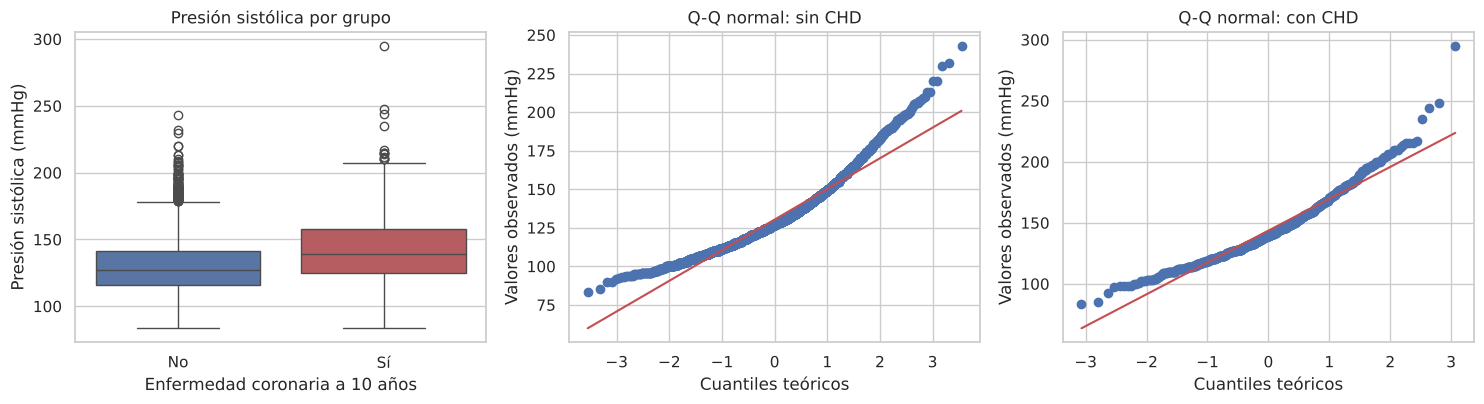

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.boxplot(data=df, x="TenYearCHD", y="sysBP", hue="TenYearCHD", legend=False,
            ax=ax[0], palette=[COLORES["principal"], COLORES["riesgo"]])
ax[0].set_xticks([0, 1], ["No", "Sí"])
ax[0].set(xlabel="Enfermedad coronaria a 10 años", ylabel="Presión sistólica (mmHg)",
          title="Presión sistólica por grupo")
for a, (nombre, x) in zip(ax[1:], [("sin CHD", sano), ("con CHD", chd)]):
    stats.probplot(x, dist="norm", plot=a)
    a.set(title=f"Q-Q normal: {nombre}", xlabel="Cuantiles teóricos",
          ylabel="Valores observados (mmHg)")
guardar_figura("p3_fig1_sysbp_supuestos")

En ambos grupos se rechaza la normalidad (p < 0,001) y hay asimetría positiva, lo que también se ve en la curvatura de los gráficos Q-Q. La prueba de Levene rechaza la igualdad de varianzas: el grupo con CHD tiene mayor dispersión.

Decisión:
- La falta de normalidad no impide usar la prueba *t*: con n₀ = 3.596 y n₁ = 644, por el Teorema Central del Límite la media muestral tiene una distribución aproximadamente normal.
- Como las varianzas son distintas, se usa la prueba *t* de Welch, que no supone varianzas iguales.
- Como comprobación, se aplica también la prueba U de Mann-Whitney, que no requiere normalidad.

#### 2.4 Ejecución de la prueba

In [36]:
t = stats.ttest_ind(chd, sano, equal_var=False)
ic = t.confidence_interval(confidence_level=1 - ALPHA)
dif = chd.mean() - sano.mean()
d = d_cohen(chd, sano)
mw = stats.mannwhitneyu(chd, sano, alternative="two-sided")

print(f"Diferencia de medias (CHD - sin CHD): {dif:.2f} mmHg")
print(f"IC 95% de la diferencia: [{ic.low:.2f}, {ic.high:.2f}] mmHg")
print(f"t de Welch = {t.statistic:.2f} | gl = {t.df:.1f} | p = {t.pvalue:.2e}")
print(f"d de Cohen = {d:.2f}")
print(f"Mann-Whitney U = {mw.statistic:.0f} | p = {mw.pvalue:.2e}")
print("Decisión:", decision(t.pvalue))

Diferencia de medias (CHD - sin CHD): 13.28 mmHg
IC 95% de la diferencia: [11.11, 15.45] mmHg
t de Welch = 12.01 | gl = 783.8 | p = 1.25e-30
d de Cohen = 0.62
Mann-Whitney U = 1519932 | p = 1.05e-36
Decisión: se rechaza H0


#### 2.5 Interpretación

Como p < 0,05, se rechaza H₀. La presión sistólica media es distinta entre ambos grupos. Quienes desarrollan enfermedad coronaria tienen, en promedio, 13,3 mmHg más que quienes no la desarrollan (143,6 frente a 130,3 mmHg). El IC del 95 % para la diferencia va de 11,1 a 15,5 mmHg y no incluye cero.

La prueba U de Mann-Whitney también encuentra diferencias entre los grupos. Sin embargo, esta prueba compara los rangos de las distribuciones y no específicamente las medias, por lo que se utiliza como comprobación frente a la asimetría.

El tamaño del efecto es moderado (d de Cohen = 0,62). Para el proyecto, este resultado respalda la inclusión de la presión sistólica en los análisis posteriores. Aun así, la comparación es bivariada y no demuestra causalidad. Parte de la diferencia podría explicarse por la edad u otros factores.

### 3. Prueba 2: hábito de fumar y enfermedad coronaria

#### 3.1 Hipótesis

- **H₀:** el hábito de fumar (`currentSmoker`) y el desarrollo de enfermedad coronaria (`TenYearCHD`) son independientes.
- **H₁:** existe asociación entre el hábito de fumar y el desarrollo de enfermedad coronaria.

Ambas variables son cualitativas nominales (binarias), por lo que se usa la prueba χ² de independencia sobre una tabla de contingencia 2×2.

#### 3.2 Tabla de contingencia

In [37]:
tabla = pd.crosstab(df["currentSmoker"], df["TenYearCHD"])
tabla.index = ["No fumador", "Fumador"]
tabla.columns = ["Sin CHD", "Con CHD"]

tasas = pd.crosstab(df["currentSmoker"], df["TenYearCHD"], normalize="index")[1].mul(100).round(1)
tasas.index = tabla.index
display(tabla)
print("Tasa de CHD (%):")
print(tasas.to_string())

,Sin CHD,Con CHD
No fumador,1834,311
Fumador,1762,333


Tasa de CHD (%):
No fumador   14.50
Fumador      15.90


#### 3.3 Verificación de supuestos

1. Independencia: se asume una observación por participante de acuerdo con la descripción del dataset; no existe un identificador que permita verificarlo directamente.
2. Frecuencias esperadas: todas las celdas deben tener una frecuencia esperada de al menos 5.

In [38]:
chi = stats.chi2_contingency(tabla, correction=True)
esperadas = pd.DataFrame(chi.expected_freq, index=tabla.index, columns=tabla.columns).round(1)
display(esperadas)
print("Frecuencia esperada mínima:", esperadas.values.min())

,Sin CHD,Con CHD
No fumador,"1,819.20",325.80
Fumador,"1,776.80",318.20


Frecuencia esperada mínima: 318.2


La frecuencia esperada mínima es 318,2, muy por sobre 5, así que el supuesto se cumple. Por ser una tabla 2×2 se aplica la corrección de continuidad de Yates.

#### 3.4 Ejecución de la prueba

In [39]:
print(f"χ² = {chi.statistic:.3f} | gl = {chi.dof} | p = {chi.pvalue:.4f}")
print(f"V de Cramér = {v_cramer(chi.statistic, tabla):.3f}")
print("Decisión:", decision(chi.pvalue))

χ² = 1.497 | gl = 1 | p = 0.2211
V de Cramér = 0.019
Decisión: no se rechaza H0


#### 3.5 Interpretación

Como p = 0,22 > 0,05, no se rechaza H₀: en la muestra completa no hay evidencia de asociación entre fumar y la enfermedad coronaria. La tasa de CHD es parecida en fumadores (15,9 %) y no fumadores (14,5 %), y la V de Cramér (0,019) es casi cero.

Esto no significa que fumar no tenga efecto. Una posible explicación es la edad como variable de confusión: en este dataset los fumadores son en promedio más jóvenes que los no fumadores (47,7 vs. 51,4 años), y la edad es uno de los principales factores de riesgo coronario. Para revisarlo, se comparan las tasas de CHD dentro de tramos de edad.

Edad media por hábito de fumar:
currentSmoker
No fumador   51.40
Fumador      47.70


,No fumador,Fumador
age,,
≤ 45,4.10,8.40
46-55,13.10,18.60
> 55,24.60,28.60


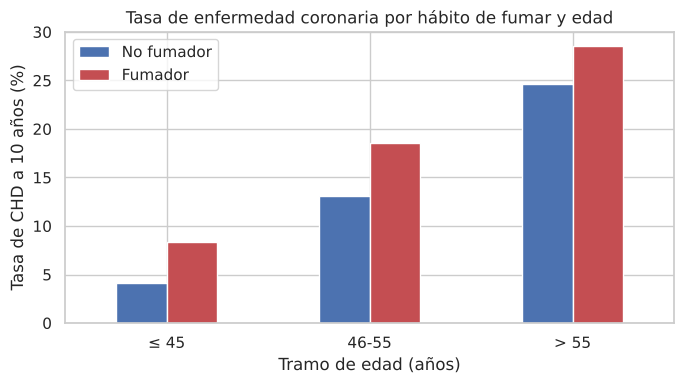

In [40]:
print("Edad media por hábito de fumar:")
print(df.groupby("currentSmoker")["age"].mean().round(1).rename({0: "No fumador", 1: "Fumador"}).to_string())

tramo_edad = pd.cut(df["age"], bins=[0, 45, 55, 100], labels=["≤ 45", "46-55", "> 55"])
estrat = (df.groupby([tramo_edad, "currentSmoker"], observed=True)["TenYearCHD"]
            .mean().mul(100).unstack().round(1))
estrat.columns = ["No fumador", "Fumador"]
display(estrat)

ax = estrat.plot(kind="bar", figsize=(7, 4), color=[COLORES["principal"], COLORES["riesgo"]], rot=0)
ax.set(xlabel="Tramo de edad (años)", ylabel="Tasa de CHD a 10 años (%)",
       title="Tasa de enfermedad coronaria por hábito de fumar y edad")
ax.legend(title="")
guardar_figura("p3_fig2_fumar_edad")

En los tres tramos de edad, los fumadores presentan una tasa observada de CHD mayor que los no fumadores. Esta comparación es descriptiva y depende de los límites elegidos para formar los tramos; tampoco elimina por completo el efecto de la edad.

Para estimar la relación entre tabaquismo y CHD controlando simultáneamente la edad y otros factores será necesario utilizar una regresión logística múltiple. Hasta realizar ese análisis, las diferencias observadas no deben interpretarse como un efecto causal.

### 4. Síntesis

| Prueba | Variables | Método | Resultado (α = 0,05) |
| --- | --- | --- | --- |
| 1 | `sysBP` vs. `TenYearCHD` | *t* de Welch y Mann-Whitney | Se rechaza H₀. La presión sistólica media es 13,3 mmHg mayor en quienes desarrollan CHD (d = 0,62). |
| 2 | `currentSmoker` vs. `TenYearCHD` | χ² de independencia | No se rechaza H₀ en la muestra completa. Por tramos de edad, los fumadores sí muestran tasas mayores. |